# Is Bayesian A/B testing immune to peeking? Rebuilding Spotify's simulations, then testing them on real data

Independent rebuild of Frånberg & Schultzberg (Spotify, 2026), *Why Spotify is not using Bayesian A/B testing*
([post](https://engineering.atspotify.com/2026/9/why-spotify-is-not-using-bayesian-a-b-testing/),
[paper, arXiv 2608.12949](https://arxiv.org/abs/2608.12949)).

The hypotheses and pass/fail rules were written down and committed **before** any simulation ran
(see `PREREGISTRATION.md`). Part 1 reproduces the paper's Settings A, B and C. Part 2 tests what the
paper does not: a skewed real metric with estimated variance, and a novelty effect.

**Assumptions** (numbered, used throughout)
1. Part 1 uses the paper's own settings (Appendix D): normal data, sigma = 1 known, effect 0.2 sigma under H1.
2. Every decision is directional: a false positive means "declared B better when B = A".
3. GST uses one-sided O'Brien-Fleming alpha spending, f(t) = 1 - Phi(z_{1-alpha}/sqrt(t)), alpha = 0.05, boundaries by numerical integration.
4. BF stopping: stop when the Bayes factor exceeds 1/alpha = 20. Mixture e-process for empirical Bayes priors: (1-p) + p * BF(V).
5. Part 2's real metric is ratings per user in MovieLens (43,584 users). It stands in for a skewed engagement metric. Real users, simulated experiments.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, os
from scipy import stats, optimize

os.makedirs("figures", exist_ok=True)
ALPHA, THR = 0.05, 20.0
Z95 = stats.norm.ppf(0.95)
RES = {}

def bf_normal(dhat, s2, V):
    """Bayes factor for N(0, V^2) prior vs point null, with dhat ~ N(delta, s2). Paper eq. 2."""
    r = s2 / (s2 + V**2)
    return np.sqrt(r) * np.exp(dhat**2 * V**2 / (2 * s2 * (s2 + V**2)))

def post_mean_mixture(dhat, s2, p, V):
    """Posterior mean under (1-p) point mass at 0 + p N(0, V^2). p=1 gives the plain Gaussian prior."""
    lam = bf_normal(dhat, s2, V)
    w = p * lam / ((1 - p) + p * lam)
    return w * dhat * V**2 / (V**2 + s2)

def binom_ci(k, n):
    lo, hi = stats.binomtest(int(k), int(n)).proportion_ci(0.95)
    return lo, hi

def gst_bounds(K, alpha=ALPHA, grid=0.005, lim=10.0):
    """One-sided O'Brien-Fleming-type Lan-DeMets boundaries on the z scale, equally spaced looks.
    Forward density recursion on the Brownian motion B(t_k) = Z_k sqrt(t_k)."""
    t = np.arange(1, K + 1) / K
    spend = 1 - stats.norm.cdf(stats.norm.ppf(1 - alpha) / np.sqrt(t))
    x = np.arange(-lim, lim + grid, grid)
    f = None
    c = np.zeros(K)
    prev_t, prev_spend = 0.0, 0.0
    for k in range(K):
        dt = t[k] - prev_t
        target = spend[k] - prev_spend
        if k == 0:
            dens = stats.norm.pdf(x, 0, np.sqrt(dt))
            cross = lambda b: 1 - stats.norm.cdf(b / np.sqrt(dt))
        else:
            cross = lambda b: np.sum(f * (1 - stats.norm.cdf((b - x) / np.sqrt(dt)))) * grid
        b = optimize.brentq(lambda b: cross(b) - target, -5, 15)
        c[k] = b / np.sqrt(t[k])
        if k == 0:
            f = np.where(x < b, dens, 0.0)
        else:
            kern = stats.norm.pdf(x[:, None] - x[None, :], 0, np.sqrt(dt))
            f = np.where(x < b, kern @ f * grid, 0.0)
        prev_t, prev_spend = t[k], spend[k]
    return c

C14, C21 = gst_bounds(14), gst_bounds(21)
print("OBF 14-look z boundaries (first, last):", C14[0].round(2), C14[-1].round(2))

OBF 14-look z boundaries (first, last): 6.15 1.88


## Part 1. Setting A: which configurations control the false positive rate?
Looks every 50 users per arm, up to 5,000 per arm, 10,000 simulated experiments under the null and 10,000 under delta = 0.2.

In [2]:
def paths(delta, n_sims, n_max, step, rng):
    """Running estimate dhat at each look. Each pair contributes a difference ~ N(delta, 2)."""
    looks = np.arange(step, n_max + 1, step)
    inc = rng.normal(delta * step, np.sqrt(2 * step), size=(n_sims, len(looks)))
    return looks, np.cumsum(inc, axis=1) / looks

def first_stop(cond):
    """Index of the first look where cond is True, or -1."""
    any_ = cond.any(axis=1)
    idx = cond.argmax(axis=1)
    return np.where(any_, idx, -1)

def run_rule(rule, looks, dh):
    s2 = 2.0 / looks
    z = dh / np.sqrt(s2)
    if rule == "naive":
        win = z > Z95; stop = first_stop(win); decided_B = stop >= 0
    elif rule == "flat_p95":          # P(B>A) under flat prior = Phi(z)
        win = stats.norm.cdf(z) > 0.95; stop = first_stop(win); decided_B = stop >= 0
    elif rule == "flat_p50_nmin350":  # decide at the first look with n >= 350
        k = np.searchsorted(looks, 350); stop = np.full(len(dh), k); decided_B = dh[:, k] > 0
    elif rule == "exp_loss":
        sd = np.sqrt(s2)
        loss_B = -dh * stats.norm.cdf(-dh / sd) + sd * stats.norm.pdf(dh / sd)   # E[max(-delta,0)]
        loss_A = dh * stats.norm.cdf(dh / sd) + sd * stats.norm.pdf(dh / sd)     # E[max(delta,0)]
        hit = np.minimum(loss_A, loss_B) < 0.02
        stop = first_stop(hit)
        decided_B = (stop >= 0) & (loss_B[np.arange(len(dh)), np.maximum(stop, 0)] < loss_A[np.arange(len(dh)), np.maximum(stop, 0)])
    elif rule.startswith("bf_"):
        V = float(rule.split("_")[1])
        hit = bf_normal(dh, s2, V) > THR
        stop = first_stop(hit)
        decided_B = (stop >= 0) & (dh[np.arange(len(dh)), np.maximum(stop, 0)] > 0)
    n_stop = np.where(stop >= 0, looks[np.maximum(stop, 0)], np.nan)
    return decided_B, n_stop

rng = np.random.default_rng(2026)
looks, d0 = paths(0.0, 10_000, 5_000, 50, rng)
_, d1 = paths(0.2, 10_000, 5_000, 50, rng)
paper_A = {"naive": 0.303, "flat_p95": 0.303, "flat_p50_nmin350": 0.501, "exp_loss": 0.499, "bf_0.2": 0.019, "bf_0.4": 0.016}
rowsA = []
for rule, ref in paper_A.items():
    dB0, _ = run_rule(rule, looks, d0)
    dB1, n1 = run_rule(rule, looks, d1)
    fpr = dB0.mean()
    lo, hi = binom_ci(dB0.sum(), len(dB0))
    rowsA.append(dict(rule=rule, paper_fpr=ref, my_fpr=round(fpr, 4), ci_lo=round(lo, 4), ci_hi=round(hi, 4),
                      power=round(dB1.mean(), 3), avg_n=round(np.nanmean(n1[dB1]), 0), pass_=abs(fpr - ref) <= 0.015))
tabA = pd.DataFrame(rowsA)
print(tabA.to_string(index=False))
RES["setting_A"] = tabA.to_dict(orient="records")
RES["H1_pass"] = bool(tabA.pass_.all())
# The paper's BF rates (0.019, 0.016) are about twice my directional rates. Counting a crossing in either direction:
RES["bf_any_direction"] = {V: float((bf_normal(d0, 2.0 / looks, V) > THR).any(1).mean()) for V in (0.2, 0.4)}
print("BF crossing in either direction:", RES["bf_any_direction"])

            rule  paper_fpr  my_fpr  ci_lo  ci_hi  power  avg_n  pass_
           naive      0.303  0.3100 0.3009 0.3192  1.000  183.0   True
        flat_p95      0.303  0.3100 0.3009 0.3192  1.000  183.0   True
flat_p50_nmin350      0.501  0.4967 0.4869 0.5065  0.996  350.0   True
        exp_loss      0.499  0.5008 0.4910 0.5106  0.954   86.0   True
          bf_0.2      0.019  0.0111 0.0091 0.0134  1.000  505.0   True
          bf_0.4      0.016  0.0083 0.0066 0.0103  1.000  527.0   True
BF crossing in either direction: {0.2: 0.0214, 0.4: 0.0165}


## Part 1. Setting B: Bayes factor stopping vs group sequential testing
Up to 1,000 users per arm. GST looks 14 or 21 times; BF methods look after every pair (their best case).
Empirical Bayes priors as in the paper: oracle (p = 0.30, V = 0.20), winner-selected corpus (p = 1, V = 0.23), pooled programs (p = 0.51, V = 0.37).

In [3]:
def pair_paths(delta, n_sims, n_max, rng):
    n = np.arange(1, n_max + 1)
    return n, np.cumsum(rng.normal(delta, np.sqrt(2), size=(n_sims, n_max)), axis=1) / n

def gst_run(n, dh, C):
    K = len(C)
    look_n = np.round(np.arange(1, K + 1) / K * n[-1]).astype(int)
    dl = dh[:, look_n - 1]
    z = dl / np.sqrt(2.0 / look_n)
    stop = first_stop(z > C)
    dB = stop >= 0
    est = np.where(dB, dl[np.arange(len(dl)), np.maximum(stop, 0)], np.nan)
    nst = np.where(dB, look_n[np.maximum(stop, 0)], np.nan)
    return dB, nst, est

def bf_run(n, dh, p, V):
    s2 = 2.0 / n
    e = (1 - p) + p * bf_normal(dh, s2, V)
    stop = first_stop(e > THR)
    i = np.maximum(stop, 0); r = np.arange(len(dh))
    dB = (stop >= 0) & (dh[r, i] > 0)
    est = np.where(dB, post_mean_mixture(dh[r, i], s2[i], p, V), np.nan)
    nst = np.where(dB, n[i], np.nan)
    return dB, nst, est

rng = np.random.default_rng(99)
nB, b0 = pair_paths(0.0, 5_000, 1_000, rng)
_, b1 = pair_paths(0.2, 5_000, 1_000, rng)
configs = {"GST 14 looks": ("gst", C14), "GST 21 looks": ("gst", C21),
           "BF Gaussian V=0.2": ("bf", (1.0, 0.2)), "BF EB oracle": ("bf", (0.30, 0.20)),
           "BF EB winner-selected": ("bf", (1.0, 0.23)), "BF EB pooled": ("bf", (0.51, 0.37))}
paper_B = {"GST 14 looks": (0.051, 0.996, 430, 5.9), "GST 21 looks": (0.052, 0.997, 421, 6.3),
           "BF Gaussian V=0.2": (0.011, 0.941, 405, 3.0), "BF EB oracle": (0.003, 0.899, 478, 2.7),
           "BF EB winner-selected": (0.013, 0.953, 388, 4.5), "BF EB pooled": (0.007, 0.910, 432, 10.4)}
rowsB = []
for name, (kind, arg) in configs.items():
    f = (lambda d: gst_run(nB, d, arg)) if kind == "gst" else (lambda d: bf_run(nB, d, *arg))
    dB0, _, _ = f(b0); dB1, n1, e1 = f(b1)
    mse = np.nanmean((e1[dB1] - 0.2) ** 2) * 1e3
    pf, pp, pn, pm = paper_B[name]
    rowsB.append(dict(method=name, fpr=round(dB0.mean(), 4), paper_fpr=pf, power=round(dB1.mean(), 3), paper_power=pp,
                      avg_n=round(np.nanmean(n1[dB1])), paper_avg_n=pn, mse_x1000=round(mse, 2), paper_mse=pm))
tabB = pd.DataFrame(rowsB).set_index("method")
print(tabB.to_string())
h2a = tabB.loc["GST 14 looks", "power"] > tabB.loc["BF EB oracle", "power"]
h2b = tabB["mse_x1000"].idxmin() == "BF EB oracle"
h2c = tabB.loc["BF EB pooled", "mse_x1000"] > tabB.loc["GST 14 looks", "mse_x1000"]
RES["setting_B"] = tabB.reset_index().to_dict(orient="records")
RES["H2"] = dict(gst_power_gt_oracle=bool(h2a), oracle_lowest_mse=bool(h2b), pooled_mse_gt_gst=bool(h2c), pass_=bool(h2a and h2b and h2c))
print(RES["H2"])

                          fpr  paper_fpr  power  paper_power  avg_n  paper_avg_n  mse_x1000  paper_mse
method                                                                                                
GST 14 looks           0.0500      0.051  0.996        0.996    434          430       6.01        5.9
GST 21 looks           0.0510      0.052  0.996        0.997    423          421       6.24        6.3
BF Gaussian V=0.2      0.0176      0.011  0.954        0.941    398          405       3.00        3.0
BF EB oracle           0.0050      0.003  0.901        0.899    486          478       2.58        2.7
BF EB winner-selected  0.0178      0.013  0.952        0.953    394          388       4.39        4.5
BF EB pooled           0.0118      0.007  0.913        0.910    443          432      10.11       10.4
{'gst_power_gt_oracle': True, 'oracle_lowest_mse': True, 'pooled_mse_gt_gst': True, 'pass_': True}


## Part 1. Setting C: does a bigger corpus fix a biased one?
The empirical Bayes prior is fitted (by maximum likelihood) on a corpus of past results, then used with BF stopping
on new experiments with 10 metrics. An experiment "ships" if any metric crosses (Assumption 6: up to 1,000 per arm,
looks every 10 pairs, a crossing in either direction counts; the paper does not state n_max for Setting C).

In [4]:
SIG2_C = 2 / 400  # corpus observations at n = 400 per arm

def draw_program(k, p, V, rng):
    nonnull = rng.random(k) < p
    delta = np.where(nonnull, rng.normal(0, V, k), 0.0)
    return delta + rng.normal(0, np.sqrt(SIG2_C), k)

def make_corpus(kind, Kc, rng):
    if kind == "representative":
        return draw_program(Kc, 0.30, 0.20, rng)
    if kind == "winner-selected":
        out = []
        while len(out) < Kc:
            x = draw_program(5000, 0.30, 0.20, rng)
            out.extend(x[x / np.sqrt(SIG2_C) > Z95])
        return np.array(out[:Kc])
    if kind == "pooled":
        return np.concatenate([draw_program(Kc // 2, 0.30, 0.20, rng), draw_program(Kc - Kc // 2, 0.80, 0.40, rng)])

def fit_eb(x, rng):
    def nll(th):
        p, V = th
        return -np.sum(np.log((1 - p) * stats.norm.pdf(x, 0, np.sqrt(SIG2_C)) + p * stats.norm.pdf(x, 0, np.sqrt(V**2 + SIG2_C)) + 1e-300))
    best = None
    for _ in range(5):
        r = optimize.minimize(nll, [rng.uniform(0.05, 0.95), rng.uniform(0.05, 0.6)], method="L-BFGS-B", bounds=[(1e-3, 1 - 1e-3), (1e-3, 2.0)])
        if best is None or r.fun < best.fun: best = r
    return best.x

def run_setting_C(p_hat, V_hat, rng, n_exp=2000, K=10, n_max=1000, step=10):
    looks = np.arange(step, n_max + 1, step)
    nonnull = rng.random(n_exp) < 0.30
    delta = np.where(nonnull[:, None], rng.normal(0, 0.20, (n_exp, K)), 0.0)
    inc = rng.normal(delta[..., None] * step, np.sqrt(2 * step), size=(n_exp, K, len(looks)))
    dh = np.cumsum(inc, axis=2) / looks
    e = (1 - p_hat) + p_hat * bf_normal(dh, 2.0 / looks, V_hat)
    ship = (e > THR).any(axis=(1, 2))
    fpr = ship[~nonnull].mean()
    fdr = (ship & ~nonnull).sum() / max(ship.sum(), 1)
    return fpr, fdr

rng = np.random.default_rng(77)
rowsC = []
for kind in ["representative", "winner-selected", "pooled"]:
    for Kc in [10, 30, 50, 100, 500]:
        for m in range(15):
            ph, Vh = fit_eb(make_corpus(kind, Kc, rng), rng)
            fpr, fdr = run_setting_C(ph, Vh, rng)
            rowsC.append(dict(corpus=kind, Kc=Kc, draw=m, p_hat=ph, V_hat=Vh, fpr=fpr, fdr=fdr))
fo, fdo = run_setting_C(0.30, 0.20, rng)
tabC = pd.DataFrame(rowsC)
sumC = tabC.groupby(["corpus", "Kc"])[["p_hat", "V_hat", "fpr", "fdr"]].median().round(3)
print(sumC.to_string()); print("oracle EB: FPR", round(fo, 3), "FDR", round(fdo, 3))
w = tabC[tabC.corpus == "winner-selected"]
rho, prho = stats.spearmanr(w.Kc, w.fpr)
wmed = w.groupby("Kc").fpr.median()
RES["setting_C"] = dict(summary=sumC.reset_index().to_dict(orient="records"), oracle_fpr=fo, oracle_fdr=fdo,
                        winner_spearman=rho, winner_spearman_p=prho,
                        H3_pass=bool(((wmed >= 0.10) & (wmed <= 0.30)).all() and not (rho < 0 and prho < 0.05)))
print("H3:", RES["setting_C"]["H3_pass"], "spearman", round(rho, 3), round(prho, 3))

                     p_hat  V_hat    fpr    fdr
corpus          Kc                             
pooled          10   0.639  0.346  0.140  0.239
                30   0.508  0.376  0.106  0.201
                50   0.506  0.353  0.114  0.208
                100  0.495  0.358  0.105  0.205
                500  0.508  0.374  0.113  0.212
representative  10   0.524  0.123  0.047  0.098
                30   0.344  0.199  0.064  0.128
                50   0.299  0.222  0.048  0.101
                100  0.355  0.191  0.058  0.119
                500  0.316  0.194  0.054  0.114
winner-selected 10   0.999  0.236  0.200  0.318
                30   0.999  0.230  0.198  0.315
                50   0.999  0.235  0.200  0.312
                100  0.999  0.236  0.200  0.322
                500  0.999  0.229  0.187  0.308
oracle EB: FPR 0.054 FDR 0.113
H3: True spearman -0.1 0.395


## Part 2. H4: BF stopping on a skewed real metric with estimated variance
Ratings per user in MovieLens: median 7, mean 20, max 6,614. Each simulated A/A test draws users with replacement into two arms.
The variance is estimated from the data at every look, as a platform would. Looks every 50 users per arm, up to 5,000.

In [5]:
r = pd.read_parquet("ratings.parquet", columns=["user_id"]) if os.path.exists("ratings.parquet") else None
if r is None:
    r = pd.read_parquet("https://huggingface.co/datasets/ashraq/movielens_ratings/resolve/main/data/train-00000-of-00001-8c8c7645a52d95e5.parquet", columns=["user_id"])
metric = r.groupby("user_id").size().to_numpy().astype(float)
print(f"users {len(metric):,}  median {np.median(metric):.0f}  mean {metric.mean():.1f}  max {metric.max():.0f}  skew {stats.skew(metric):.1f}")

def aa_real(values, n_sims, n_max=5000, step=50, seed=0, batch=500):
    """A/A on resampled real users. Returns standardized dhat (estimated sigma) at each look."""
    rng = np.random.default_rng(seed)
    looks = np.arange(step, n_max + 1, step)
    out = []
    for b in range(0, n_sims, batch):
        m = min(batch, n_sims - b)
        A = rng.choice(values, size=(m, len(looks), step)); B = rng.choice(values, size=(m, len(looks), step))
        sA, sB = np.cumsum(A.sum(2), 1), np.cumsum(B.sum(2), 1)
        qA, qB = np.cumsum((A**2).sum(2), 1), np.cumsum((B**2).sum(2), 1)
        mA, mB = sA / looks, sB / looks
        vA = (qA - looks * mA**2) / (looks - 1); vB = (qB - looks * mB**2) / (looks - 1)
        sig = np.sqrt((vA + vB) / 2)
        out.append((mB - mA) / sig)
    return looks, np.vstack(out)

looks_r, dstd = aa_real(metric, 10_000, seed=4)
rng = np.random.default_rng(5)
_, dnorm = paths(0.0, 10_000, 5_000, 50, rng)   # control: normal data, known sigma
rows4 = []
for label, dd in [("normal, known sigma", dnorm), ("real skewed metric, estimated sigma", dstd)]:
    for rule in ["naive", "bf_0.2"]:
        dB, _ = run_rule(rule, looks_r, dd)
        lo, hi = binom_ci(dB.sum(), len(dB))
        rows4.append(dict(data=label, rule=rule, fpr=round(dB.mean(), 4), ci_lo=round(lo, 4), ci_hi=round(hi, 4)))
    # GST with 14 equally spaced looks over the same horizon
    idx = np.round(np.arange(1, 15) / 14 * len(looks_r)).astype(int) - 1
    z = dd[:, idx] / np.sqrt(2.0 / looks_r[idx])
    dB = (z > C14).any(1); lo, hi = binom_ci(dB.sum(), len(dB))
    rows4.append(dict(data=label, rule="gst_14", fpr=round(dB.mean(), 4), ci_lo=round(lo, 4), ci_hi=round(hi, 4)))
tab4 = pd.DataFrame(rows4); print(tab4.to_string(index=False))
bf_real = tab4[(tab4.data.str.startswith("real")) & (tab4.rule == "bf_0.2")].iloc[0]
# where do the false positives happen?
s2 = 2.0 / looks_r
hit = bf_normal(dstd, s2, 0.2) > THR
st = first_stop(hit); fp = (st >= 0) & (dstd[np.arange(len(dstd)), np.maximum(st, 0)] > 0)
early_share = (looks_r[st[fp]] <= 500).mean()
print(f"share of BF false positives at n <= 500 per arm: {early_share:.2f}")
RES["H4"] = dict(table=tab4.to_dict(orient="records"), early_share=float(early_share),
                 pass_=bool(bf_real.fpr <= 0.05 and bf_real.ci_hi < 0.06))
print("H4 pass:", RES["H4"]["pass_"])

users 43,584  median 7  mean 20.5  max 6614  skew 46.9


                               data   rule    fpr  ci_lo  ci_hi
                normal, known sigma  naive 0.3178 0.3087 0.3270
                normal, known sigma bf_0.2 0.0114 0.0094 0.0137
                normal, known sigma gst_14 0.0499 0.0457 0.0544
real skewed metric, estimated sigma  naive 0.3076 0.2986 0.3168
real skewed metric, estimated sigma bf_0.2 0.0077 0.0061 0.0096
real skewed metric, estimated sigma gst_14 0.0470 0.0429 0.0513
share of BF false positives at n <= 500 per arm: 0.32
H4 pass: True


## Part 2. H5: a novelty effect
The true lift starts at twice its long-run value (0.2 sigma) and decays to the long-run value (0.1 sigma) with a half-life of
one third of the run. Users arrive evenly over the run, up to 1,000 per arm. Which method's estimate overstates the long-run lift more?

In [6]:
D_LR, HALF = 0.1, 1 / 3
def novelty_paths(n_sims, n_max, rng):
    n = np.arange(1, n_max + 1)
    eff = D_LR * (1 + np.exp(-np.log(2) * (n / n_max) / HALF))
    return n, np.cumsum(rng.normal(eff, np.sqrt(2), size=(n_sims, n_max)), axis=1) / n

rng = np.random.default_rng(11)
nN, dN = novelty_paths(5_000, 1_000, rng)
gB, gn, ge = gst_run(nN, dN, C14)
bB, bn, be = bf_run(nN, dN, 1.0, 0.2)
# MLE at the BF stopping point, for reference
s2N = 2.0 / nN; stb = first_stop(bf_normal(dN, s2N, 0.2) > THR)
be_mle = np.where(bB, dN[np.arange(len(dN)), np.maximum(stb, 0)], np.nan)
fixed = dN[:, -1]
avg_true = D_LR * (1 + np.mean(np.exp(-np.log(2) * (nN / nN[-1]) / HALF)))
relb = lambda e: np.nanmean(e) / D_LR - 1
boot = []
rb = np.random.default_rng(0)
for _ in range(2000):
    i = rb.integers(0, len(dN), len(dN))
    boot.append(np.nanmean(np.where(bB[i], be[i], np.nan)) / D_LR - np.nanmean(np.where(gB[i], ge[i], np.nan)) / D_LR)
lo5, hi5 = np.percentile(boot, [2.5, 97.5])
H5 = dict(detect_gst=float(gB.mean()), detect_bf=float(bB.mean()),
          avg_stop_gst=float(np.nanmean(gn)), avg_stop_bf=float(np.nanmean(bn)),
          relbias_gst=float(relb(ge[gB])), relbias_bf_postmean=float(relb(be[bB])), relbias_bf_mle=float(relb(be_mle[bB])),
          relbias_fixed_n=float(relb(fixed)), avg_true_effect_over_run_rel=float(avg_true / D_LR - 1),
          diff_ci=[float(lo5), float(hi5)])
H5["pass_"] = bool(H5["relbias_bf_postmean"] > H5["relbias_gst"] and lo5 > 0)
RES["H5"] = H5
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in H5.items()})

{'detect_gst': 0.938, 'detect_bf': 0.731, 'avg_stop_gst': 507.515, 'avg_stop_bf': 413.664, 'relbias_gst': 0.953, 'relbias_bf_postmean': 1.118, 'relbias_bf_mle': 1.652, 'relbias_fixed_n': 0.431, 'avg_true_effect_over_run_rel': 0.42, 'diff_ci': [0.14629339148945852, 0.18545949778100643], 'pass_': True}


## Part 2. H6: the winner's curse, with a right and a wrong prior
A program where 30% of experiments have a real effect drawn from N(0, 0.2^2). So the "oracle" prior is truly calibrated here.

In [7]:
rng = np.random.default_rng(21)
NS = 5_000
nonnull = rng.random(NS) < 0.30
delta6 = np.where(nonnull, rng.normal(0, 0.2, NS), 0.0)
n6 = np.arange(1, 1001)
d6 = np.cumsum(rng.normal(delta6[:, None], np.sqrt(2), size=(NS, 1000)), axis=1) / n6
def winners(kind, arg):
    if kind == "gst":
        dB, _, e = gst_run(n6, d6, arg); return dB, e, e
    p, V = arg
    s2 = 2.0 / n6
    st = first_stop((1 - p) + p * bf_normal(d6, s2, V) > THR)
    i = np.maximum(st, 0); rr = np.arange(NS)
    dB = (st >= 0) & (d6[rr, i] > 0)
    mle = np.where(dB, d6[rr, i], np.nan)
    pm = np.where(dB, post_mean_mixture(d6[rr, i], s2[i], p, V), np.nan)
    return dB, pm, mle
rows6 = []
for name, kind, arg in [("GST 14 looks (MLE)", "gst", C14), ("BF + EB oracle", "bf", (0.30, 0.20)), ("BF + EB pooled", "bf", (0.51, 0.37))]:
    dB, pm, mle = winners(kind, arg)
    rows6.append(dict(method=name, n_winners=int(dB.sum()), false_winners=int((dB & ~nonnull).sum()),
                      bias_reported=float(np.nanmean(pm[dB] - delta6[dB])), mae_reported=float(np.nanmean(np.abs(pm[dB] - delta6[dB]))),
                      bias_mle_at_stop=float(np.nanmean(mle[dB] - delta6[dB]))))
tab6 = pd.DataFrame(rows6).set_index("method"); print(tab6.round(4).to_string())
o, g, pl = tab6.loc["BF + EB oracle"], tab6.loc["GST 14 looks (MLE)"], tab6.loc["BF + EB pooled"]
RES["H6"] = dict(table=tab6.reset_index().to_dict(orient="records"),
                 oracle_bias_lt_mle=bool(abs(o.bias_reported) < abs(o.bias_mle_at_stop)),
                 pooled_mae_gt_gst=bool(pl.mae_reported > g.mae_reported))
RES["H6"]["pass_"] = RES["H6"]["oracle_bias_lt_mle"] and RES["H6"]["pooled_mae_gt_gst"]
print("H6:", {k: v for k, v in RES["H6"].items() if k != "table"})

                    n_winners  false_winners  bias_reported  mae_reported  bias_mle_at_stop
method                                                                                     
GST 14 looks (MLE)        696            173         0.0553        0.0776            0.0553
BF + EB oracle            398             19         0.0003        0.0674            0.0726
BF + EB pooled            419             31         0.0729        0.1044            0.1251
H6: {'oracle_bias_lt_mle': True, 'pooled_mae_gt_gst': True, 'pass_': True}


## Figures and results

{'H1_pass': True, 'H2': True, 'H4': True, 'H5': True, 'H6': True} H3 True


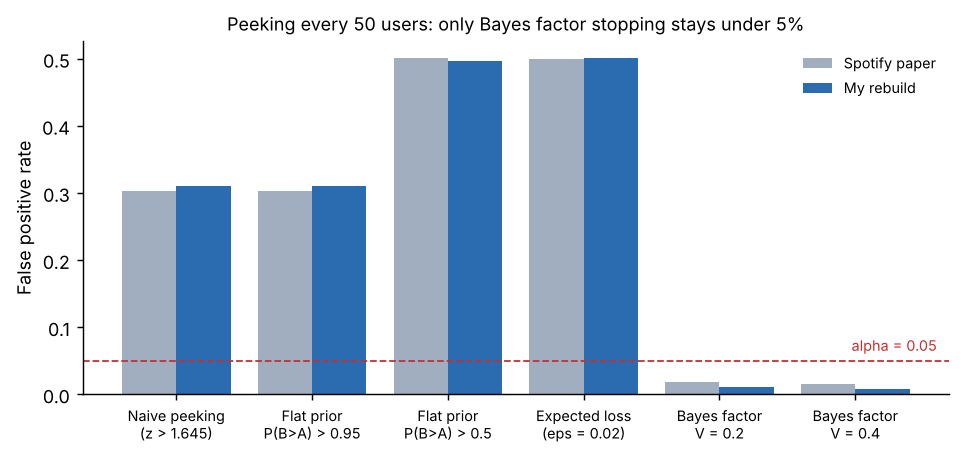

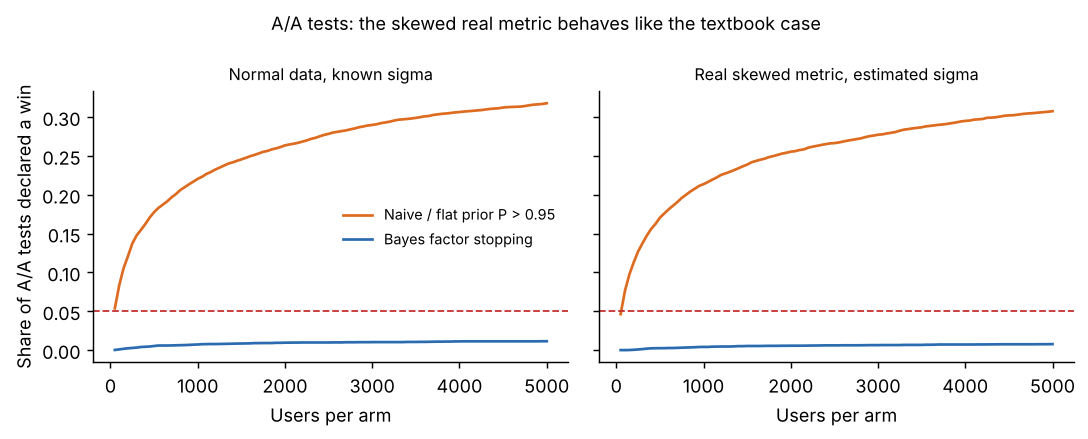

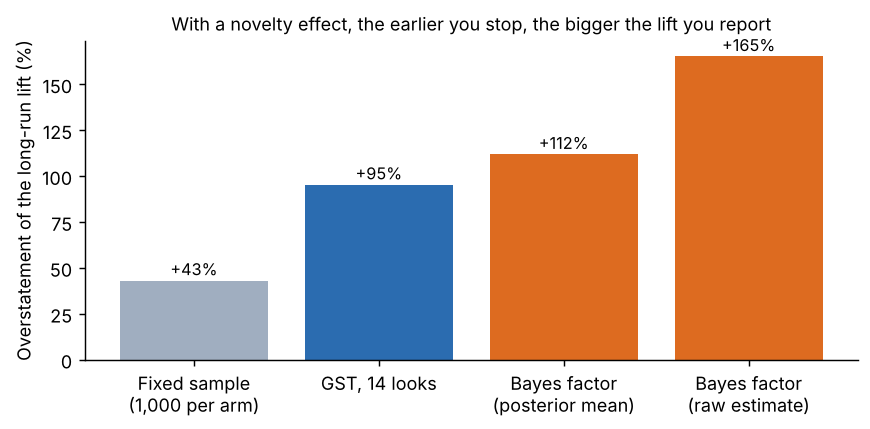

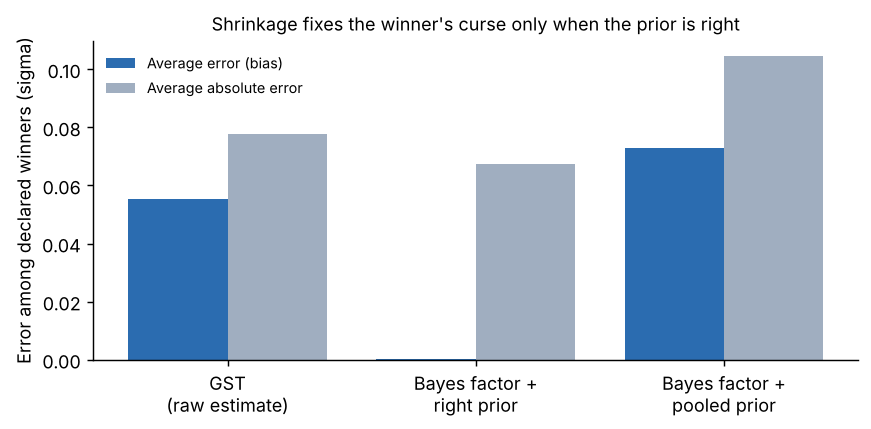

In [8]:
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREY, RED = "#2b6cb0", "#dd6b20", "#a0aec0", "#c53030"

# Fig 1: Setting A, mine vs paper
fig, ax = plt.subplots(figsize=(7.5, 3.6))
lab = {"naive": "Naive peeking\n(z > 1.645)", "flat_p95": "Flat prior\nP(B>A) > 0.95", "flat_p50_nmin350": "Flat prior\nP(B>A) > 0.5",
       "exp_loss": "Expected loss\n(eps = 0.02)", "bf_0.2": "Bayes factor\nV = 0.2", "bf_0.4": "Bayes factor\nV = 0.4"}
x = np.arange(len(tabA))
ax.bar(x - 0.2, tabA.paper_fpr, 0.4, color=GREY, label="Spotify paper")
ax.bar(x + 0.2, tabA.my_fpr, 0.4, color=BLUE, label="My rebuild")
ax.axhline(0.05, color=RED, ls="--", lw=1); ax.text(5.6, 0.065, "alpha = 0.05", color=RED, ha="right", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([lab[r] for r in tabA.rule], fontsize=8)
ax.set_ylabel("False positive rate"); ax.set_title("Peeking every 50 users: only Bayes factor stopping stays under 5%", fontsize=10)
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig("figures/fig1_setting_a.png", dpi=200)

# Fig 2: cumulative FPR over the run, normal vs real skewed metric
fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.4), sharey=True)
for ax, (title, dd) in zip(axs, [("Normal data, known sigma", dnorm), ("Real skewed metric, estimated sigma", dstd)]):
    s2 = 2.0 / looks_r
    naive_first = first_stop(dd / np.sqrt(s2) > Z95)
    hitb = bf_normal(dd, s2, 0.2) > THR; stb_ = first_stop(hitb)
    bfB = (stb_ >= 0) & (dd[np.arange(len(dd)), np.maximum(stb_, 0)] > 0)
    cum_naive = [(naive_first >= 0) & (naive_first <= k) for k in range(len(looks_r))]
    cum_bf = [bfB & (stb_ <= k) for k in range(len(looks_r))]
    ax.plot(looks_r, [c.mean() for c in cum_naive], color=ORANGE, label="Naive / flat prior P > 0.95")
    ax.plot(looks_r, [c.mean() for c in cum_bf], color=BLUE, label="Bayes factor stopping")
    ax.axhline(0.05, color=RED, ls="--", lw=1)
    ax.set_title(title, fontsize=9); ax.set_xlabel("Users per arm")
axs[0].set_ylabel("Share of A/A tests declared a win"); axs[0].legend(frameon=False, fontsize=8)
fig.suptitle("A/A tests: the skewed real metric behaves like the textbook case", fontsize=10); fig.tight_layout()
fig.savefig("figures/fig2_cumulative_fpr.png", dpi=200)

# Fig 3: novelty effect
fig, ax = plt.subplots(figsize=(6.8, 3.4))
names = ["Fixed sample\n(1,000 per arm)", "GST, 14 looks", "Bayes factor\n(posterior mean)", "Bayes factor\n(raw estimate)"]
vals = [H5["relbias_fixed_n"], H5["relbias_gst"], H5["relbias_bf_postmean"], H5["relbias_bf_mle"]]
ax.bar(names, np.array(vals) * 100, color=[GREY, BLUE, ORANGE, ORANGE])
for i, v in enumerate(vals): ax.text(i, v * 100 + 3, f"+{v*100:.0f}%", ha="center", fontsize=9)
ax.set_ylabel("Overstatement of the long-run lift (%)")
ax.set_title("With a novelty effect, the earlier you stop, the bigger the lift you report", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig3_novelty.png", dpi=200)

# Fig 4: winner's curse
fig, ax = plt.subplots(figsize=(6.8, 3.4))
t6 = tab6.reset_index()
ax.bar(np.arange(3) - 0.2, t6.bias_reported, 0.4, color=BLUE, label="Average error (bias)")
ax.bar(np.arange(3) + 0.2, t6.mae_reported, 0.4, color=GREY, label="Average absolute error")
ax.set_xticks(range(3)); ax.set_xticklabels(["GST\n(raw estimate)", "Bayes factor +\nright prior", "Bayes factor +\npooled prior"])
ax.set_ylabel("Error among declared winners (sigma)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Shrinkage fixes the winner's curse only when the prior is right", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig4_winners_curse.png", dpi=200)

def clean(o):
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items()}
    if isinstance(o, list): return [clean(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
json.dump(clean(RES), open("figures/results.json", "w"), indent=1)
print({k: RES[k]["pass_"] if isinstance(RES[k], dict) and "pass_" in RES[k] else RES[k] for k in ["H1_pass", "H2", "H4", "H5", "H6"]}, "H3", RES["setting_C"]["H3_pass"])

## Scorecard

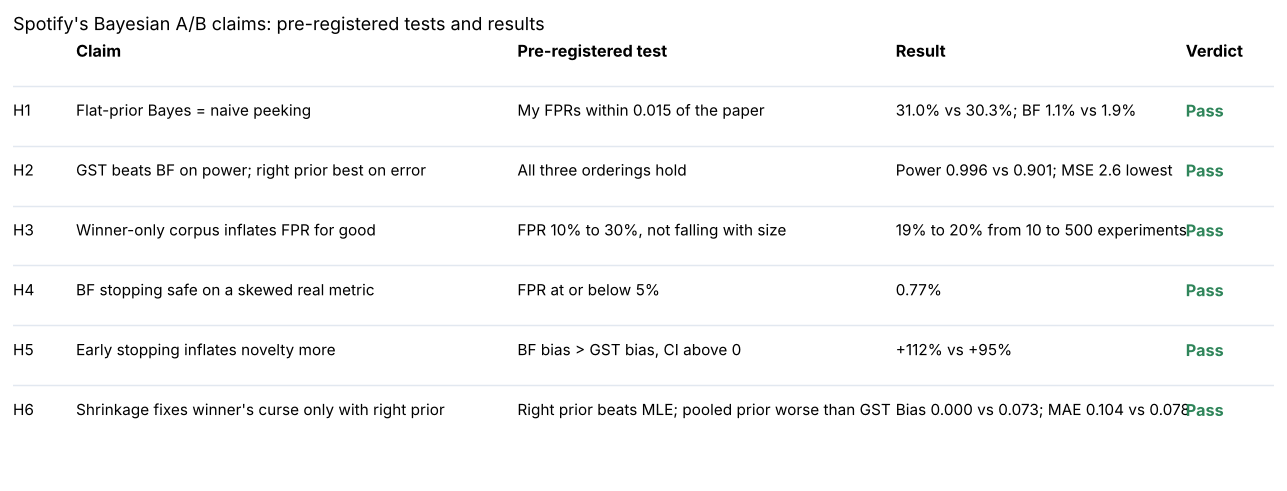

In [9]:
def scorecard(rows, title, path):
    """rows: (id, claim, test, result, verdict). Verdict colors: Pass green, Fail red, other amber."""
    colors = {"Pass": "#2f855a", "Fail": "#c53030"}
    fig, ax = plt.subplots(figsize=(10, 0.48 * len(rows) + 1.0)); ax.axis("off")
    heads = ["", "Claim", "Pre-registered test", "Result", "Verdict"]
    xs = [0.0, 0.05, 0.40, 0.70, 0.93]
    y = 1.0; step = 1.0 / (len(rows) + 1.3)
    for x, h in zip(xs, heads): ax.text(x, y, h, fontsize=9, fontweight="bold", va="top", transform=ax.transAxes)
    for r in rows:
        y -= step
        ax.plot([0, 1], [y + step * 0.25] * 2, color="#e2e8f0", lw=0.8, transform=ax.transAxes)
        for x, t in zip(xs[:4], r[:4]): ax.text(x, y, t, fontsize=8.5, va="top", transform=ax.transAxes, wrap=True)
        ax.text(xs[4], y, r[4], fontsize=9, fontweight="bold", va="top", color=colors.get(r[4].split()[0], "#b7791f"), transform=ax.transAxes)
    ax.set_title(title, fontsize=10, loc="left")
    fig.tight_layout(); fig.savefig(path, dpi=200, bbox_inches="tight")

A_ = {r["rule"]: r for r in RES["setting_A"]}; B_ = {r["method"]: r for r in RES["setting_B"]}
scorecard([
    ("H1", "Flat-prior Bayes = naive peeking", "My FPRs within 0.015 of the paper", f"{A_['flat_p95']['my_fpr']*100:.1f}% vs 30.3%; BF {A_['bf_0.2']['my_fpr']*100:.1f}% vs 1.9%", "Pass"),
    ("H2", "GST beats BF on power; right prior best on error", "All three orderings hold", f"Power {B_['GST 14 looks']['power']:.3f} vs {B_['BF EB oracle']['power']:.3f}; MSE {B_['BF EB oracle']['mse_x1000']:.1f} lowest", "Pass"),
    ("H3", "Winner-only corpus inflates FPR for good", "FPR 10% to 30%, not falling with size", "19% to 20% from 10 to 500 experiments", "Pass"),
    ("H4", "BF stopping safe on a skewed real metric", "FPR at or below 5%", f"{RES['H4']['table'][4]['fpr']*100:.2f}%", "Pass"),
    ("H5", "Early stopping inflates novelty more", "BF bias > GST bias, CI above 0", f"+{RES['H5']['relbias_bf_postmean']*100:.0f}% vs +{RES['H5']['relbias_gst']*100:.0f}%", "Pass"),
    ("H6", "Shrinkage fixes winner's curse only with right prior", "Right prior beats MLE; pooled prior worse than GST", "Bias 0.000 vs 0.073; MAE 0.104 vs 0.078", "Pass"),
], "Spotify's Bayesian A/B claims: pre-registered tests and results", "figures/fig0_scorecard.png")